# Лабораторная работа №3
## DBSCAN
Манухин Константин  
Вариант 3 - Экономика городов  

**Цель работы** - познакомиться с работой алгоритма DBSCAN на примере анализа городов по экономическим показателям

Гипотезы:
- Города могут быть похожи друг на друга по экономическим параметрам, поэтому их можно разбить на кластеры
- В данных будут выбросы - города с сильно отличающимися условиями от остальных

Описание данных:
- Название города
- Среднее рабочих часов по 12 профессиям
- Индекс цен на 112 товаров и услуг
- Индекс зарплаты за час работы после вычета налогов


# Подготовка
Импортируем данные, найдем выбросы, стандартизируем

In [176]:
# Импорт библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gdown
import itertools
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, cophenet
from scipy.spatial.distance import pdist

In [177]:
# Константы
RANDOM_STATE = 42 # сид рандома для воспроизводимости
FILENAME = "data.csv"
NAME_COL = "City"
NUM_COLS = ["Work", "Price", "Salary"]

In [178]:
# Загрузка данных с гугл-диска
def download_data(file_id: str, filename: str, sep: str=";", dec: str=","):
    url = f"https://drive.google.com/uc?id={file_id}"
    gdown.download(url, filename)
    return pd.read_csv(FILENAME, sep=sep, decimal=dec)


# Ссылка на данные - https://drive.google.com/file/d/1CeHPnsBl7XGlnxzSryNnYx1FteILxOdM/view?usp=drive_link
# Из файла видно, что разделитель колонок - ";" а для дробных - ","
file_id = "1CeHPnsBl7XGlnxzSryNnYx1FteILxOdM"
df = download_data(file_id, FILENAME)
df.head(3)

Downloading...
From: https://drive.google.com/uc?id=1CeHPnsBl7XGlnxzSryNnYx1FteILxOdM
To: /content/data.csv
100%|██████████| 1.18k/1.18k [00:00<00:00, 3.69MB/s]


,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5


In [179]:
# Типы данных загрузились правильно
df.dtypes

,0
City,object
Work,int64
Price,float64
Salary,float64


In [180]:
# Данные - 48 городов: имя + 3 числовых параметра
print(df.shape)
df.head(3)

(48, 4)


,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5


In [181]:
# Нет пропусков. Возможно они заменены на какое-то значение
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    48 non-null     object 
 1   Work    48 non-null     int64  
 2   Price   48 non-null     float64
 3   Salary  48 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 1.6+ KB


In [182]:
# Статистики по данным
def desc(df: pd.DataFrame, r: int=2):
    return df[NUM_COLS].describe().round(r)

# Посмотрим на статистики - подозрительное значение "-9999"
# Из-за них некоторые статистики уехали в отрицательный диапазон
desc(df)

,Work,Price,Salary
count,48.00,48.00,48.00
mean,1384.96,68.86,-378.73
std,2404.90,21.78,2027.34
min,-9999.00,30.30,-9999.00
25%,1740.75,49.65,12.25
50%,1834.50,70.50,40.30
75%,1972.75,81.70,58.70
max,2375.00,115.50,100.00


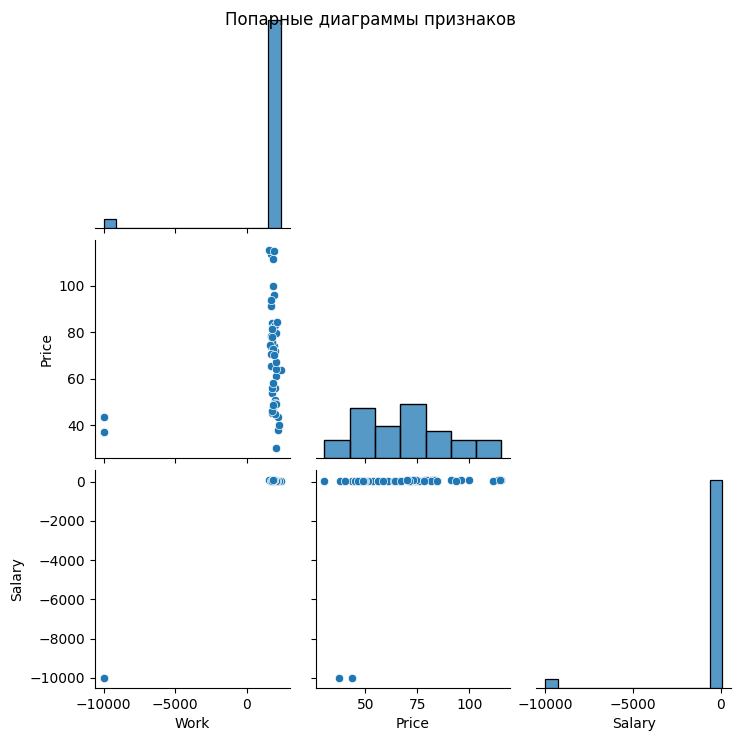

In [183]:
# Отображение попарных графиков
def pairs(df: pd.DataFrame):
    g = sns.pairplot(df, corner=True)
    g.fig.suptitle("Попарные диаграммы признаков")
    return g

# На графиках видно, что эти выбросы в -9999 портят вся картину
pairs(df)

In [184]:
# У Каира и Джакарты 2 из 3 значений = -9999.
# Предлагаю просто отбросить эти строки
df[df.eq(-9999).any(axis=1)]

,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


In [185]:
# Удаление строк с определенным значением
def clean_data(df: pd.DataFrame, filter_value: int):
    mask = ~df.eq(filter_value).any(axis=1)
    return df[mask].reset_index(drop=True)

# Удаляем выбросы
df_filtered = clean_data(df, -9999)
print(df_filtered.shape)
df_filtered.head(3)

(46, 4)


,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5


Отобразим статистики и графики - данные выглядят вполне себе нормально, без выбросов


In [186]:
# Статистики
desc(df_filtered)

,Work,Price,Salary
count,46.00,46.00,46.00
mean,1879.91,70.10,39.55
std,174.34,21.39,24.76
min,1583.00,30.30,2.70
25%,1745.25,51.78,14.38
50%,1849.00,70.95,43.65
75%,1976.25,81.90,59.70
max,2375.00,115.50,100.00


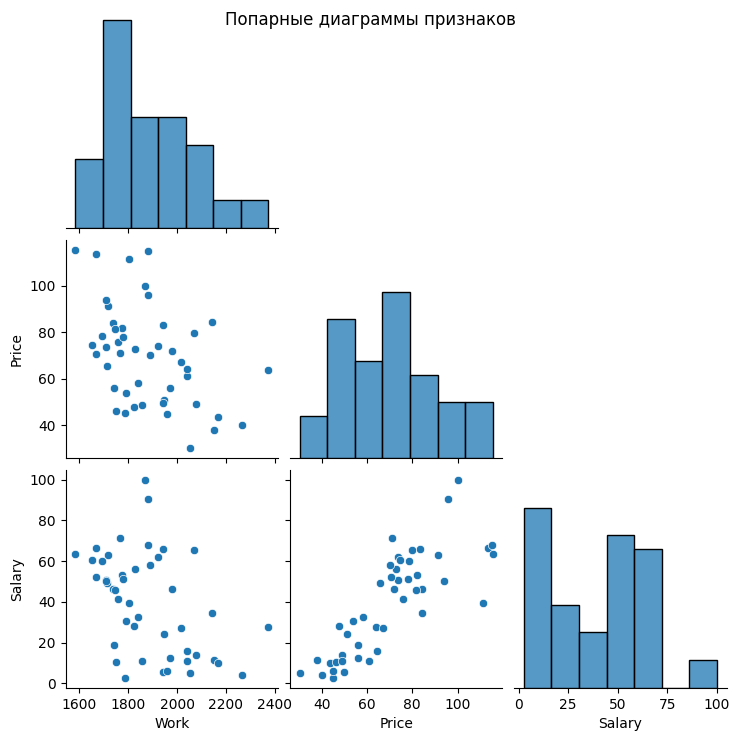

In [187]:
# Парные диаграммы
pairs(df_filtered)

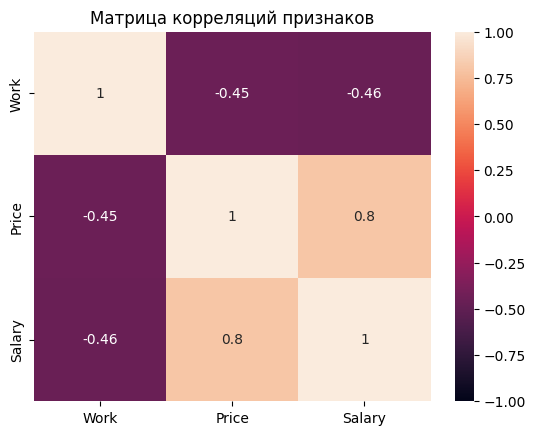

In [188]:
# Отображение матрицы корреляций признаков
def heatmap(df: pd.DataFrame):
    corr = df[NUM_COLS].corr()
    sns.heatmap(corr, annot=True, vmin=-1, vmax=1)
    plt.title("Матрица корреляций признаков")

# Корреляции - похоже что цены связвны с зарплатами.
# Логично, люди могут позволить себе больше
heatmap(df_filtered)

In [189]:
# Скейлинг данных
def scale_data(df: pd.DataFrame):
    scaler = StandardScaler()
    df_new = df.copy()
    df_new[NUM_COLS] = scaler.fit_transform(df[NUM_COLS])
    return df_new

# Сразу подготовим стандартизарованный набор данных
df_scaled = scale_data(df_filtered)
print(df_scaled.shape)
df_scaled.head(3)

(46, 4)


,City,Work,Price,Salary
0,Amsterdam,-0.962166,-0.212712,0.386095
1,Athens,-0.509827,-0.770489,-0.373488
2,Bogota,1.577891,-1.522069,-1.145323


In [190]:
desc(df_scaled)

,Work,Price,Salary
count,46.00,46.00,46.00
mean,0.00,-0.00,0.00
std,1.01,1.01,1.01
min,-1.72,-1.88,-1.50
25%,-0.78,-0.87,-1.03
50%,-0.18,0.04,0.17
75%,0.56,0.56,0.82
max,2.87,2.15,2.47


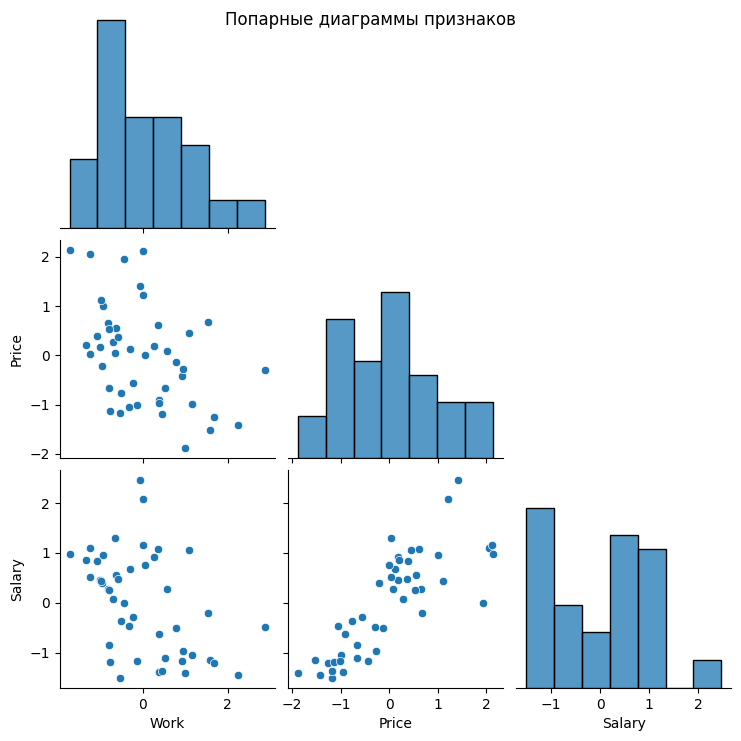

In [191]:
pairs(df_scaled)

Результаты раздела:
- Пропуски были заменены на "-9999" - отбросили 2 строки. осталось 46 строк с данными
- Есть сильная корреляция цен и зарплат
- Выполнили стандартизацию
- Сразу так кластеров не видно, мб на графике Salary/Price можно провести линию между 2 группами точек

# Выбор количества кластеров
Попробуем увидеть число кластеров  
Для визуализации всех данных на одном графике применим мой любимый метод - PCA

In [192]:
# PCA - объясняемая дисперсия
def pca_var(df: pd.DataFrame, comp: int=2):
    X = df[NUM_COLS].to_numpy()
    pca_full = PCA().fit(X)
    return np.cumsum(pca_full.explained_variance_ratio_)

# Для начала посмотрим насколько много дисперсии объясняется 2 компонентами
# Сведение до 2 компонент объясняет 93% дисперсии
print("Доля объяснения: ", pca_var(df_scaled))

Доля объяснения:  [0.72006788 0.9346159  1.        ]


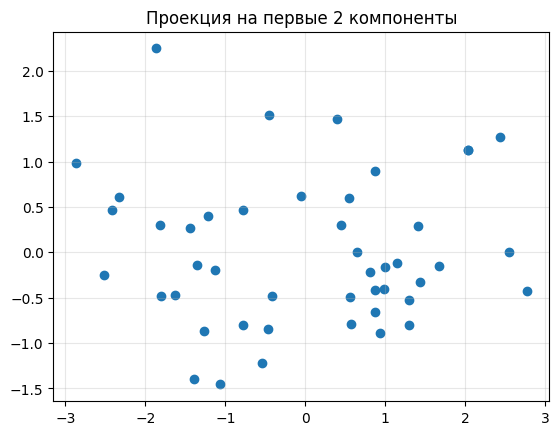

In [193]:
# Сведение к 2 главным компонентам
def pca_fit(df: pd.DataFrame, comp=2):
    pca = PCA(n_components=comp)
    X = df[NUM_COLS].to_numpy()
    X_pca = pca.fit_transform(X)
    return X_pca

# Отображения 2 главных компонент
def pca_plot(df: pd.DataFrame, comp: int=2):
    X_pca = pca_fit(df)
    plt.scatter(X_pca[:, 0], X_pca[:, 1])
    plt.title("Проекция на первые 2 компоненты")
    plt.grid(True, alpha=0.3)

# Сводим к 2 компонентам и отобразим на графике
pca_plot(df_scaled)

Выводы раздела:
- 2 компоненты отражают 93% дисперсии
- Видно 2 больших кластера
- Сверху видно отдельную точку - возможно выброс
- Справа 4 точки - возможно выбросы, или 1 или 2 кластера
- Итого 2-4 кластера

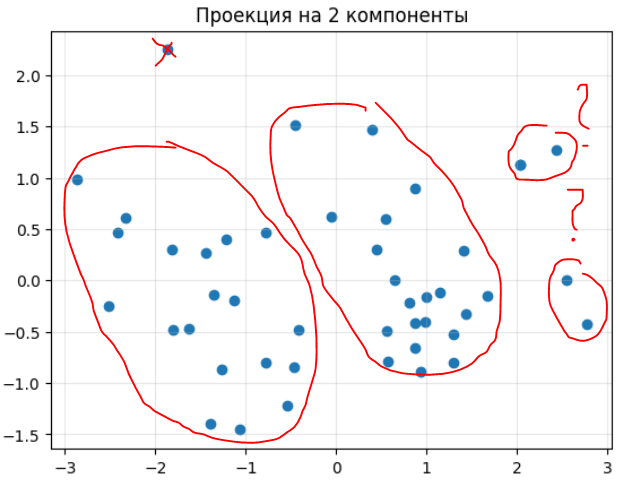

# Иерархический анализ
Построим дендрограммы, проверим число кластеров

Расстояния между объектами - посмотрим евклидово:
- Евклидово - наиболее логичное
- Манхэттенское - более устойчиво к выбросам, но мы уже избавились от выбросов
- Косинусное здесь не применимо, потому что оно смотрит на углы между векторами
- Хеммингово - для бинарных признаков

Расстояния между кластерами - проверим все:
- Single - минимальное расстояние между кластерами, находит вытянутые кластеры
- Complete - максимальное расстояние между кластерами
- Average - усреднённое расстояние между кластерами
- Ward - минимизирует внутрикластерную дисперсию

Количество кластеров буду подбирать, пока две большие группы не разрежутся или есть большие вертикальные линии

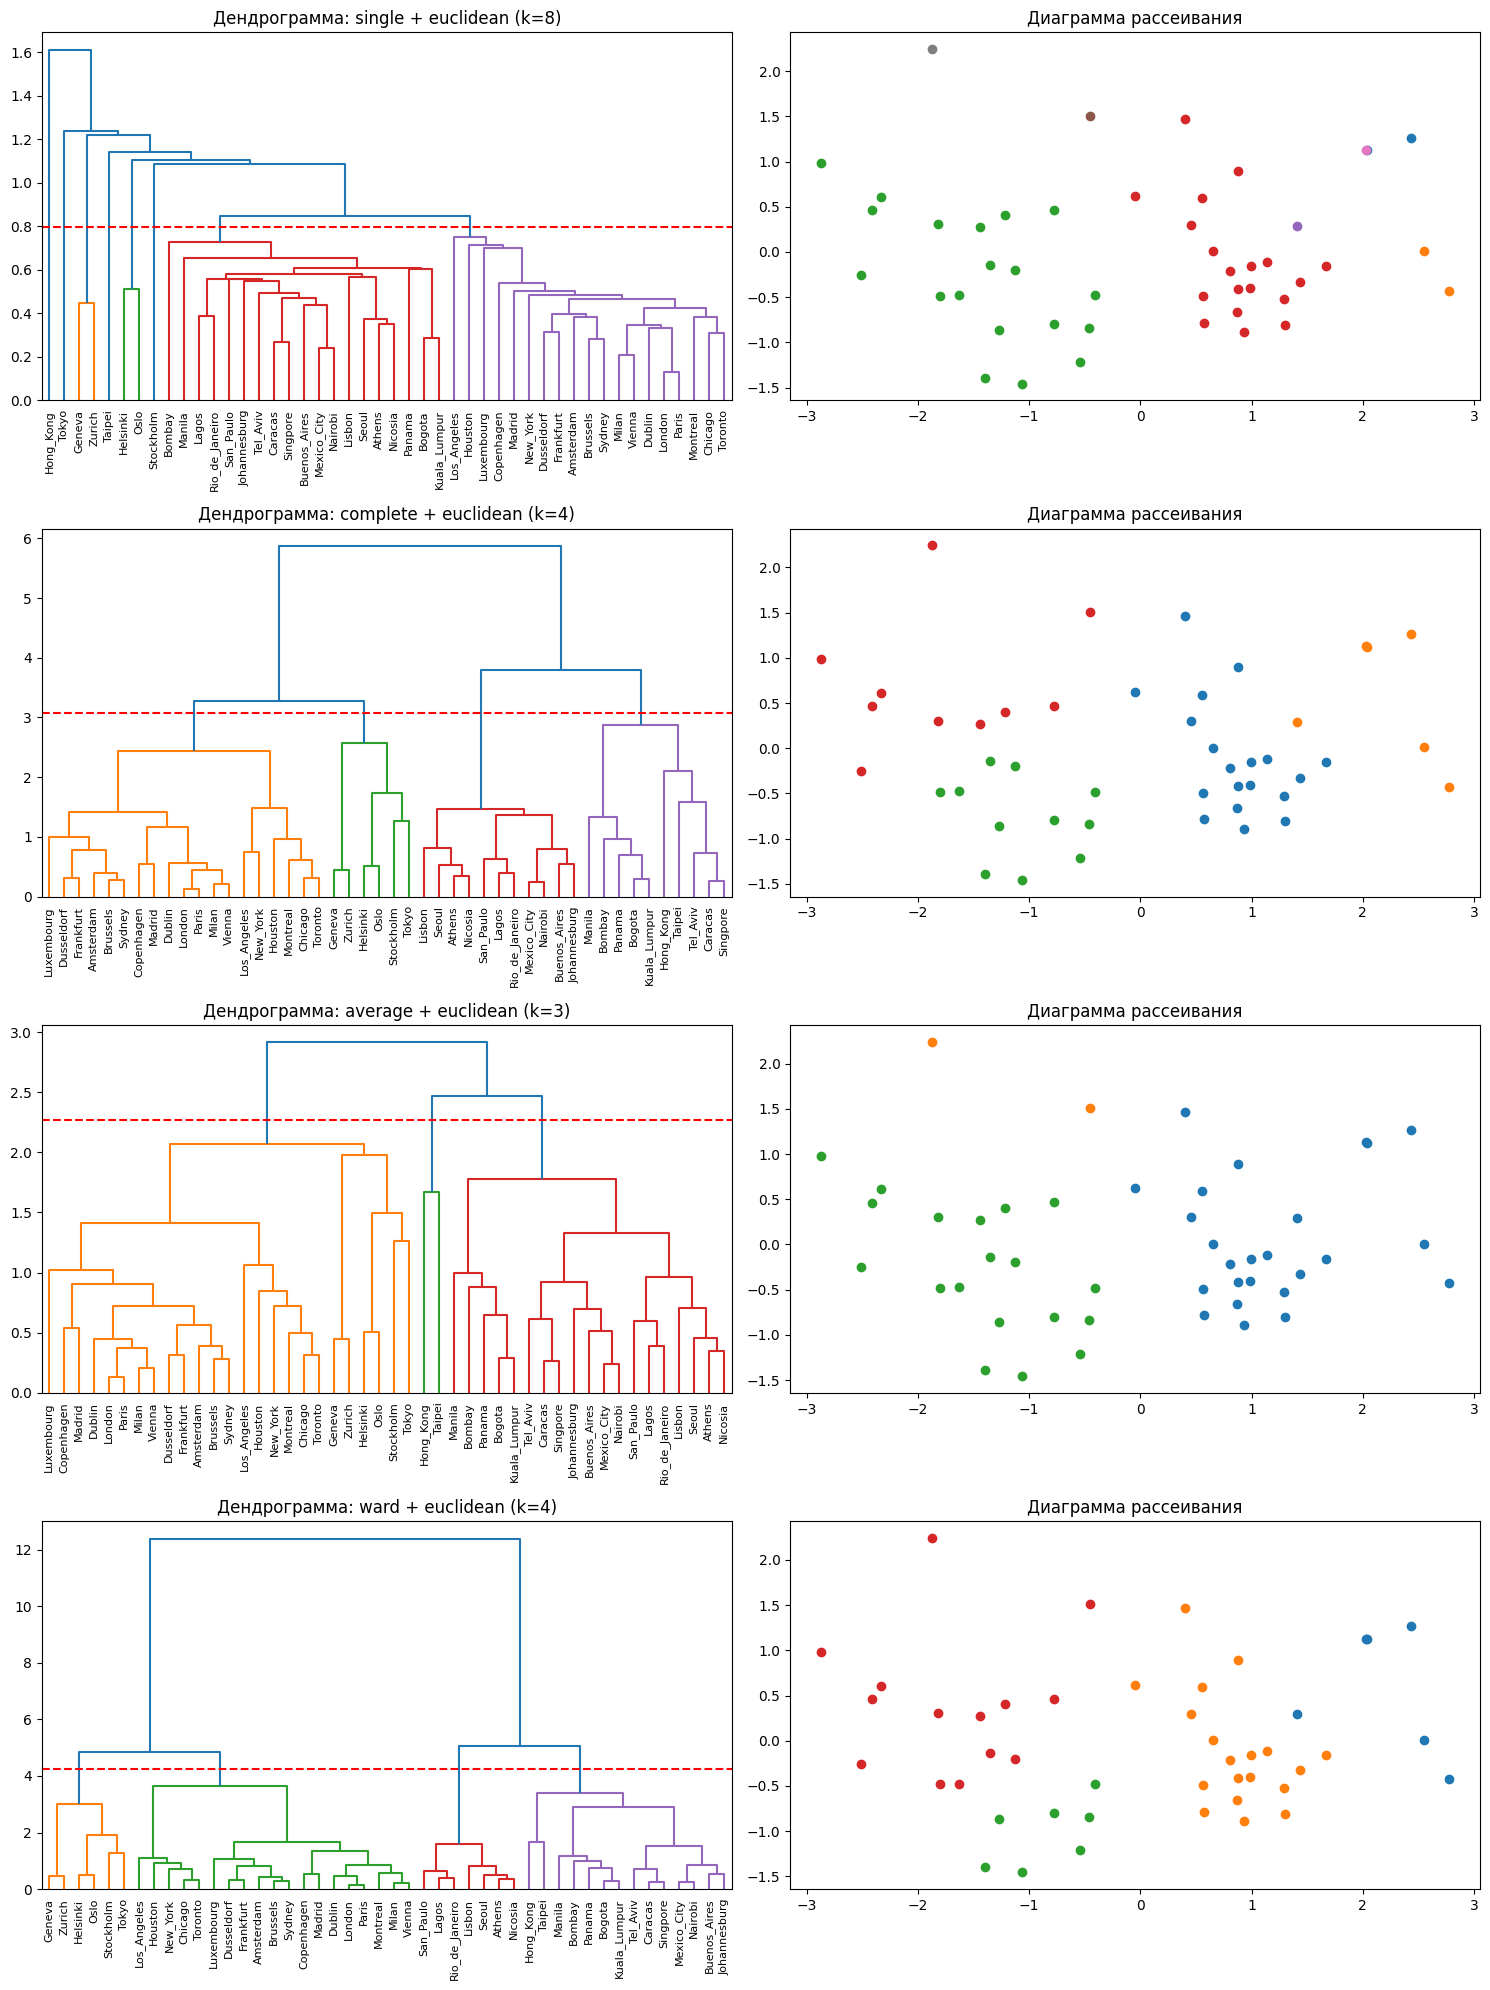

In [194]:
# Разделение на кластеры по дендрограмме
def get_clusters(df: pd.DataFrame, method: str, metric: str, k: int):
    X = df[NUM_COLS].to_numpy()
    # Процесс объединения кластеров по выбранному методу
    link = linkage(X, method=method, metric=metric)
    # Метки кластеров
    cl_labels = fcluster(link, t=k, criterion="maxclust")
    return link, cl_labels

# Построение дендрограммы
def plot_dendrogram(df: pd.DataFrame, method: str, metric: str, k: int, ax):
    cities = df[NAME_COL].tolist()
    link, cl_labels = get_clusters(df, method, metric, k)
    # Диаграмма
    h = (link[-k, 2] + link[-k+1, 2]) / 2
    dendrogram(link, ax=ax, color_threshold=h, labels=cities)
    ax.set_title(f"Дендрограмма: {method} + {metric} (k={k})")
    # Разрез на кластеры
    ax.axhline(y=h, color="red", linestyle="--")
    return cl_labels

# Отображение кластеров на графике
def plot_clusters(df: pd.DataFrame, cl_labels: np.ndarray, ax):
    X_pca = pca_fit(df)
    for cl in sorted(set(cl_labels)):
        mask = (cl_labels == cl)
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1])
        ax.set_title(f"Диаграмма рассеивания")


# Зададим перебираемые методы объединения кластеров, метрику
# и количество кластеров
linkages = ["single", "complete", "average", "ward"]
metric = "euclidean"
clusters = [8, 4, 3, 4]

fig, axes = plt.subplots(4, 2, figsize=(15, 20))
for i, (k, l) in enumerate(zip(clusters, linkages)):
    cl_clusters = plot_dendrogram(df_scaled, l, metric, k, axes[i, 0])
    plot_clusters(df_scaled, cl_clusters, axes[i, 1])

plt.tight_layout()

Выводы раздела:
- В зависимости от метода объединения кластеров дендрограмма будет указыват на разное число кластеров
- Пока что основная версия - 4 кластера
- Ward и Complete помог увидеть 4 кластера, которые не были видны до этого
- Single помог найти много городов, которые потенциально являются выбросами

## Интерпретация кластеров дендрограммы
Попробуем интерпретировать кластеры, полученные дендрограммой

In [195]:
# Средние значения по числовым столбцам для каждого кластера
def cluster_stats(df: pd.DataFrame, cl_labels: np.ndarray):
    tmp = df.copy()
    tmp["cluster"] = cl_labels

    stats = tmp.groupby("cluster")[NUM_COLS].mean().round(2)
    stats.insert(0, "n", tmp.groupby("cluster").size())
    stats["cities"] = tmp.groupby("cluster")[NAME_COL].apply(lambda s: ", ".join(map(str, s)))
    return stats


Single - находит выбросы.  
Группы 1-3, 6-8 содержат <= 2 элемента, которые отличаются от основных групп.  
3 - Высокая нагрузка, очень низкие цены и зарплаты. Работяги  
4 - Низкая нагрузка, высокие цены и зарплаты. Мажоры


In [196]:
ind = 0
l = linkages[ind]
k = clusters[ind]
print(f"Таблица средних значений для {l} + {metric}")
link, cl_labels = get_clusters(df_scaled, l, metric, k)
stats = cluster_stats(df_scaled, cl_labels)
display(stats)

Таблица средних значений для single + euclidean


,n,Work,Price,Salary,cities
cluster,,,,,
1,2,-0.03,1.32,2.27,"Geneva, Zurich"
2,2,-1.48,2.10,1.05,"Helsinki, Oslo"
3,19,0.46,-0.94,-1.01,"Athens, Bogota, Bombay, Buenos_Aires, Caracas,..."
4,19,-0.51,0.35,0.64,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
5,1,-0.43,1.95,-0.01,Stockholm
6,1,1.54,0.67,-0.21,Taipei
7,1,0.00,2.12,1.16,Tokyo
8,1,2.87,-0.30,-0.48,Hong_Kong


Complete - 4 группы  
1 - Низкая нагрузка, высокие цены и зарплаты. Мажоры  
2 - Низкая нагрузка, очень высокие цены и зарплаты. Золотые воротнички  
3 - Средняя нагрузка, очень низкие цены и зарплаты. Работяги  
4 - Очень высокая нагрузка, низкие цены и очень низкие зарплаты. Бедные трудоголики  

In [197]:
ind = 1
l = linkages[ind]
k = clusters[ind]
print(f"Таблица средних значений для {l} + {metric}")
link, cl_labels = get_clusters(df_scaled, l, metric, k)
stats = cluster_stats(df_scaled, cl_labels)
display(stats)

Таблица средних значений для complete + euclidean


,n,Work,Price,Salary,cities
cluster,,,,,
1,19,-0.51,0.35,0.64,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
2,6,-0.58,1.82,1.30,"Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich"
3,11,-0.14,-0.91,-0.94,"Athens, Buenos_Aires, Johannesburg, Lagos, Lis..."
4,10,1.47,-0.75,-0.96,"Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lump..."


Average - 3 группы  
1 - Низкая нагрузка, высокие цены и зарплаты. Мажоры   
2 - Очень высокая нагрузка, средние цены и низкие зарплаты. Трудоголики  
3 - Высокая нагрузка, очень низкие цены и зарплаты. Работяги

In [198]:
ind = 2
l = linkages[ind]
k = clusters[ind]
print(f"Таблица средних значений для {l} + {metric}")
link, cl_labels = get_clusters(df_scaled, l, metric, k)
stats = cluster_stats(df_scaled, cl_labels)
display(stats)

Таблица средних значений для average + euclidean


,n,Work,Price,Salary,cities
cluster,,,,,
1,25,-0.53,0.70,0.80,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
2,2,2.20,0.19,-0.34,"Hong_Kong, Taipei"
3,19,0.46,-0.94,-1.01,"Athens, Bogota, Bombay, Buenos_Aires, Caracas,..."


Ward - 4 группы  
1 - Низкая нагрузка, очень высокие цены и зарплаты. Золотые воротнички  
2 - Низкая нагрузка, средние цены и высокие зарплаты. Мажоры  
3 - Низкая нагрузка, очень низкие цены и зарплаты. Лентяи  
4 - Очень высокая нагрузка, очень низкие цены и зарплаты. Бедные трудоголики  

In [199]:
ind = 3
l = linkages[ind]
k = clusters[ind]
print(f"Таблица средних значений для {l} + {metric}")
link, cl_labels = get_clusters(df_scaled, l, metric, k)
stats = cluster_stats(df_scaled, cl_labels)
display(stats)

Таблица средних значений для ward + euclidean


,n,Work,Price,Salary,cities
cluster,,,,,
1,6,-0.58,1.82,1.30,"Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich"
2,19,-0.51,0.35,0.64,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
3,7,-0.47,-0.91,-0.83,"Athens, Lagos, Lisbon, Nicosia, Rio_de_Janeiro..."
4,14,1.17,-0.80,-1.01,"Bogota, Bombay, Buenos_Aires, Caracas, Hong_Ko..."


# K-Means
- Применим метод K-Means и разобьём на 2-7 кластеров
- Проверим метрики локтя, Silhouette (больше лучше), Calinski–Harabasz (больше лучше), Davies–Bouldin (меньше лучше)
- Посмотрим средние значения по кластерам
- Сравним с выводами дендрограммы

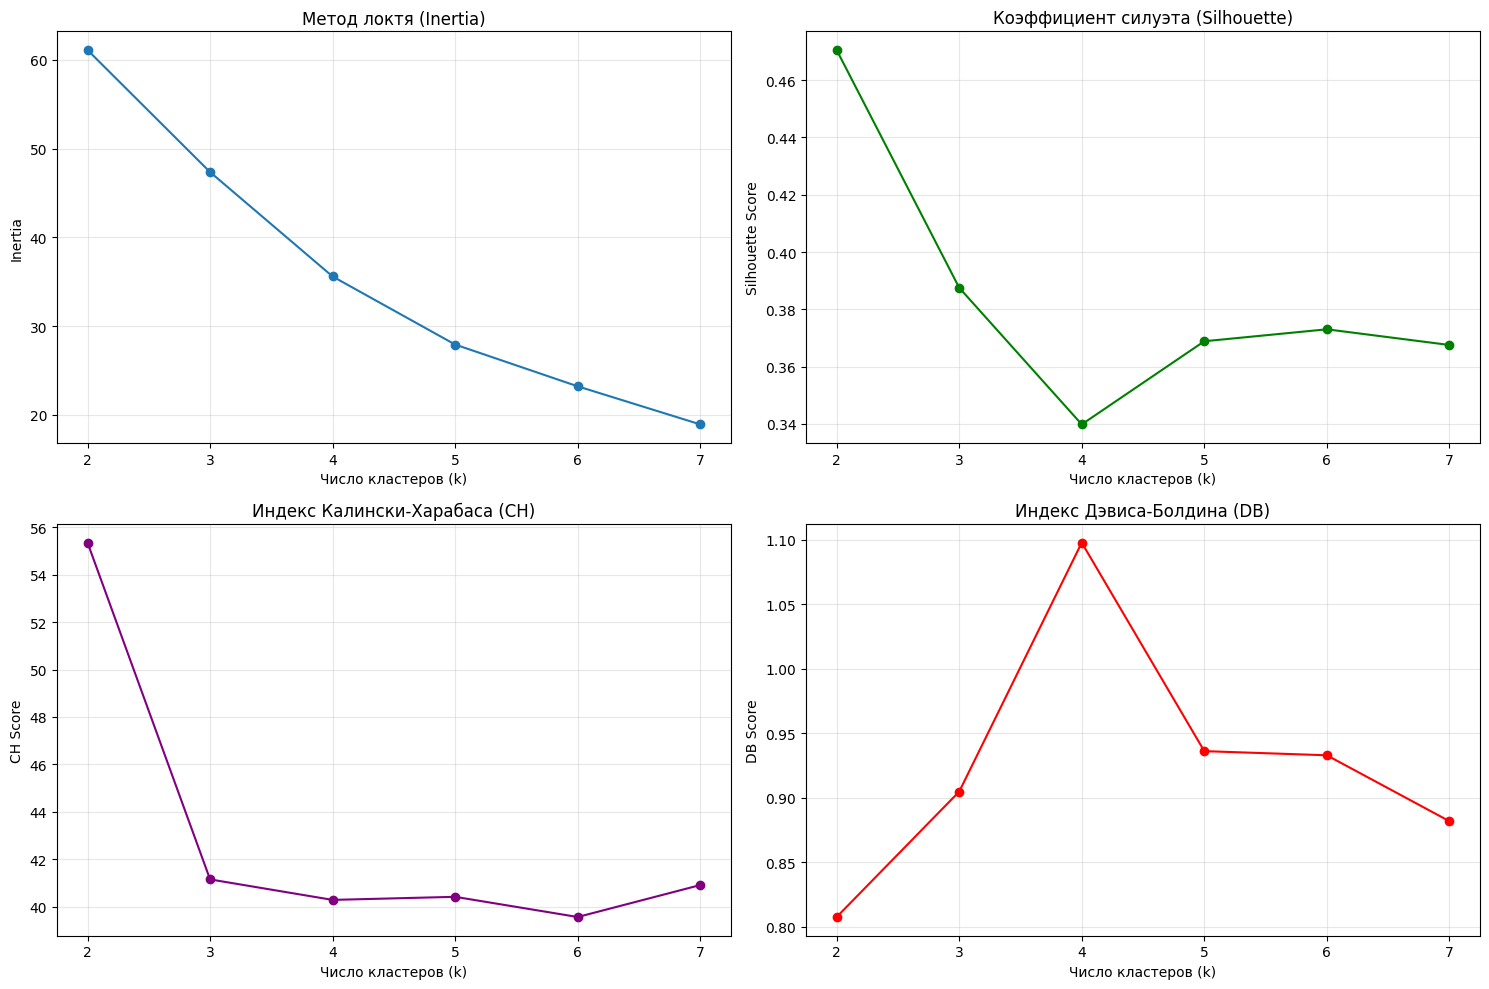

In [200]:
# Отображение метрик кластеризации на графике
def plot_kmeans_metrics(df: pd.DataFrame, min_k: int, max_k: int):
    X = df[NUM_COLS].to_numpy()
    inertias = []
    silhouettes = []
    calinski = []
    davies = []

    k_range = range(2, max_k + 1)
    for k in k_range:
        # Кластеризуем
        kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        labels = kmeans.fit_predict(X)

        # Считаем метрики
        inertias.append(kmeans.inertia_)
        silhouettes.append(silhouette_score(X, labels))
        calinski.append(calinski_harabasz_score(X, labels))
        davies.append(davies_bouldin_score(X, labels))

    # Отображаем метрики
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    # Метод локтя
    axes[0, 0].plot(k_range, inertias, marker='o')
    axes[0, 0].set_title('Метод локтя (Inertia)')
    axes[0, 0].set_xlabel('Число кластеров (k)')
    axes[0, 0].set_ylabel('Inertia')
    axes[0, 0].grid(True, alpha=0.3)

    # Silhouette
    axes[0, 1].plot(k_range, silhouettes, marker='o', color='green')
    axes[0, 1].set_title('Коэффициент силуэта (Silhouette)')
    axes[0, 1].set_xlabel('Число кластеров (k)')
    axes[0, 1].set_ylabel('Silhouette Score')
    axes[0, 1].grid(True, alpha=0.3)

    # Calinski-Harabasz
    axes[1, 0].plot(k_range, calinski, marker='o', color='purple')
    axes[1, 0].set_title('Индекс Калински-Харабаса (CH)')
    axes[1, 0].set_xlabel('Число кластеров (k)')
    axes[1, 0].set_ylabel('CH Score')
    axes[1, 0].grid(True, alpha=0.3)

    # Davies-Bouldin
    axes[1, 1].plot(k_range, davies, marker='o', color='red')
    axes[1, 1].set_title('Индекс Дэвиса-Болдина (DB)')
    axes[1, 1].set_xlabel('Число кластеров (k)')
    axes[1, 1].set_ylabel('DB Score')
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


min_k = 2
max_k = 7
plot_kmeans_metrics(df_scaled, min_k, max_k)


Анализ метрик:
- Локоть - нет четкого перегиба, уменьшение достаточно плавное
- Силуэт - пик в 2 кластерах, а вот 4 кластера наоборот минимум
- Калински - пик в 2 кластерах, остальные в минимуме
- Дэвис - минимум в 2 кластерах, а пик в 4

Метрики сходятся во мнении, что тут всего 2 кластера, в вот 4 кластера наоборот говорят, что не подходят.  
Попробуем визуализировать разбиение на кластеры

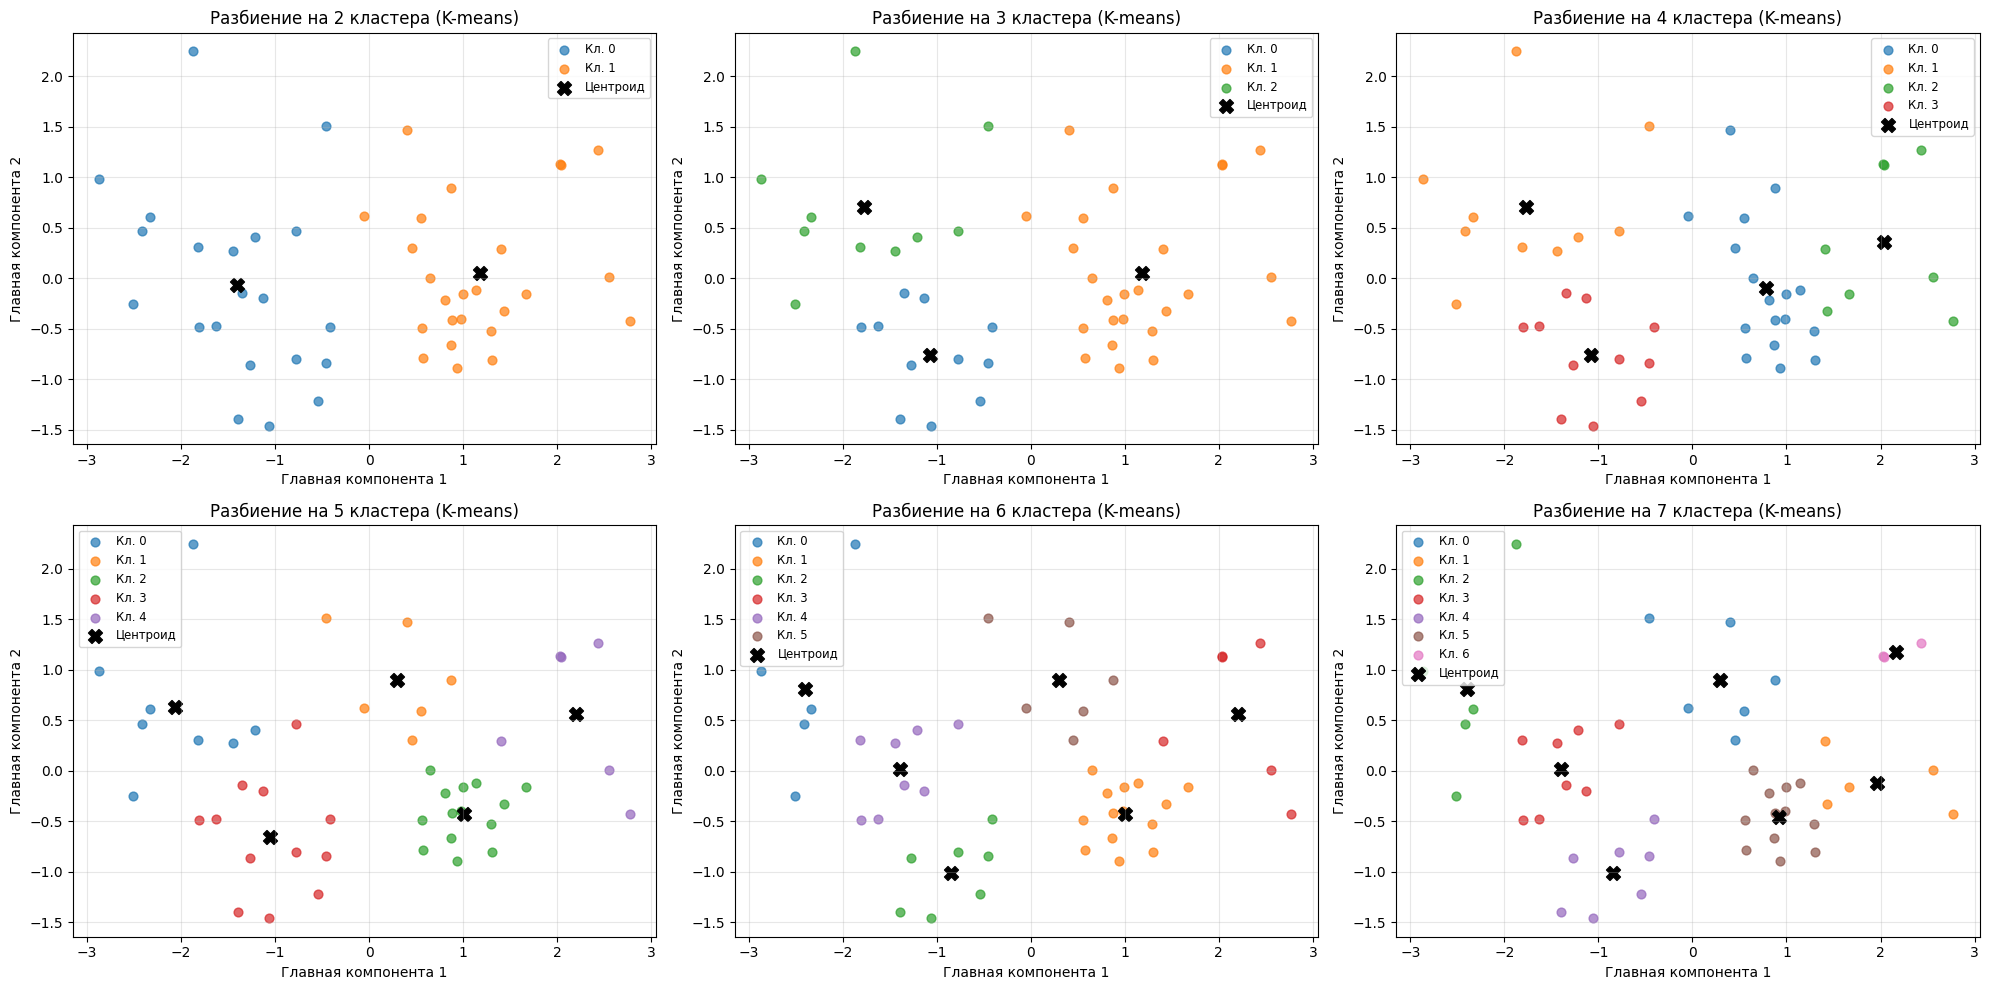

In [201]:
# Отображение разделения на кластеры с помощью K-Means
def plot_kmeans_grid(df: pd.DataFrame, min_k: int, max_k: int):
    X = df[NUM_COLS].to_numpy()
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    # Графики
    fig, axes = plt.subplots(2, 3, figsize=(20, 10))
    axes = axes.flatten()

    for i, k in enumerate(range(min_k, max_k + 1)):
        ax = axes[i]

        # Кластеризуем
        kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        cl_labels = kmeans.fit_predict(X)

        # Отрисовка точек для каждого кластера
        for cl in sorted(set(cl_labels)):
            mask = (cl_labels == cl)
            ax.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Кл. {cl}', alpha=0.7, s=40)

        # Центроиды
        centroids = kmeans.cluster_centers_
        c_pca = pca.transform(centroids)
        ax.scatter(c_pca[:, 0], c_pca[:, 1], marker='X', label='Центроид', color="black", s=100)

        ax.set_title(f'Разбиение на {k} кластера (K-means)')
        ax.set_xlabel('Главная компонента 1')
        ax.set_ylabel('Главная компонента 2')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='best', fontsize='small') # Добавим легенду для наглядности

    plt.tight_layout()
    plt.show()

# Вызов функции для наших отмасштабированных данных
plot_kmeans_grid(df_scaled, min_k, max_k)

## Интерпретация анализа K-Means
Попробуем интерпретировать данные

K-Means - 2 группы  
1 - Высокая нагрузка, очень низкие цены и зарплаты. Работяги  
2 - Низкая нагрузка, высокие цены и зарплаты. Мажоры  


In [202]:
k = 2
kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
cl_labels_km = kmeans.fit_predict(df_scaled[NUM_COLS]) + 1
print(f"Таблица средних для {k} кластеров")
stats_km = cluster_stats(df_scaled, cl_labels_km)
display(stats_km)

Таблица средних для 2 кластеров


,n,Work,Price,Salary,cities
cluster,,,,,
1,21,0.63,-0.84,-0.95,"Athens, Bogota, Bombay, Buenos_Aires, Caracas,..."
2,25,-0.53,0.70,0.80,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."


K-Means - 3 группы  
1 - Средняя нагрузка, очень низкие цены и зарплаты. Средний класс    
2 - Низкая нагрузка, высокие цены и зарплаты. Мажоры  
3 - Очень высокая нагрузка, низкие цены и очень низкие зарплаты. Бедные трудоголики

In [203]:
k = 3
kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
cl_labels_km = kmeans.fit_predict(df_scaled[NUM_COLS]) + 1
print(f"Таблица средних для {k} кластеров")
stats_km = cluster_stats(df_scaled, cl_labels_km)
display(stats_km)

Таблица средних для 3 кластеров


,n,Work,Price,Salary,cities
cluster,,,,,
1,11,-0.14,-0.91,-0.94,"Athens, Buenos_Aires, Johannesburg, Lagos, Lis..."
2,25,-0.53,0.70,0.80,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
3,10,1.47,-0.75,-0.96,"Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lump..."


K-Means - 4 группы  
1 - Низкая нагрузка, средние цены и высокая зарплата. Мажоры  
2 - Очень высокая нагрузка, низкие цены и очень низкие зарплаты. Бедные трудоголики  
3 - Очень низкая нагрузка, очень высокие цены и зарплаты. Золотые воротнички  
4 - Средняя нагрузка, очень низкие цены и зарплаты. Средний класс  


In [204]:
k = 4
kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
cl_labels_km = kmeans.fit_predict(df_scaled[NUM_COLS]) + 1
print(f"Таблица средних для {k} кластеров")
stats_km = cluster_stats(df_scaled, cl_labels_km)
display(stats_km)

Таблица средних для 4 кластеров


,n,Work,Price,Salary,cities
cluster,,,,,
1,17,-0.46,0.27,0.63,"Amsterdam, Brussels, Chicago, Dublin, Dusseldo..."
2,10,1.47,-0.75,-0.96,"Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lump..."
3,8,-0.67,1.63,1.15,"Copenhagen, Geneva, Helsinki, Madrid, Oslo, St..."
4,11,-0.14,-0.91,-0.94,"Athens, Buenos_Aires, Johannesburg, Lagos, Lis..."


K-Means - 5 групп  
1 - Очень высокая нагрузка, очень низкие цены и зарплаты. Трудоголики  
2 - Высока нагрузка, среднии цены и высокие зарплаты. Зажиточные работяги  
3 - Очень низкая нагрузка, среднии цены и высокие зарплаты. Мажоры   
4 - Средняя нагрузка, низкие цены и зарплаты. Средний класс  
5 - Низкая нагрузка, очень высокие цены и зарплаты. Золотые воротнички  


In [205]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
cl_labels_km = kmeans.fit_predict(df_scaled[NUM_COLS]) + 1
print(f"Таблица средних для {k} кластеров")
stats_km = cluster_stats(df_scaled, cl_labels_km)
display(stats_km)

Таблица средних для 5 кластеров


,n,Work,Price,Salary,cities
cluster,,,,,
1,8,1.55,-1.01,-1.11,"Bogota, Bombay, Caracas, Hong_Kong, Kuala_Lump..."
2,6,0.64,0.34,0.64,"Chicago, Houston, Los_Angeles, New_York, Taipe..."
3,14,-0.86,0.38,0.57,"Amsterdam, Brussels, Copenhagen, Dublin, Dusse..."
4,12,-0.06,-0.85,-0.90,"Athens, Buenos_Aires, Johannesburg, Lagos, Lis..."
5,6,-0.58,1.82,1.30,"Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich"


In [206]:
k = 6
kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
cl_labels_km = kmeans.fit_predict(df_scaled[NUM_COLS]) + 1
print(f"Таблица средних для {k} кластеров")
stats_km = cluster_stats(df_scaled, cl_labels_km)
display(stats_km)

Таблица средних для 6 кластеров


,n,Work,Price,Salary,cities
cluster,,,,,
1,5,1.87,-1.28,-1.14,"Bogota, Bombay, Hong_Kong, Kuala_Lumpur, Manila"
2,14,-0.86,0.38,0.57,"Amsterdam, Brussels, Copenhagen, Dublin, Dusse..."
3,7,-0.47,-0.91,-0.83,"Athens, Lagos, Lisbon, Nicosia, Rio_de_Janeiro..."
4,6,-0.58,1.82,1.30,"Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich"
5,8,0.69,-0.69,-1.02,"Buenos_Aires, Caracas, Johannesburg, Mexico_Ci..."
6,6,0.64,0.34,0.64,"Chicago, Houston, Los_Angeles, New_York, Taipe..."


# DBSCAN
В этом разделе мы применим алгоритм DBSCAN, исследуем влияние параметров `eps` и `min_samples` (n), построим графики k-расстояний, выберем оптимальные параметры и интерпретируем кластеры. В конце сравним все методы кластеризации.

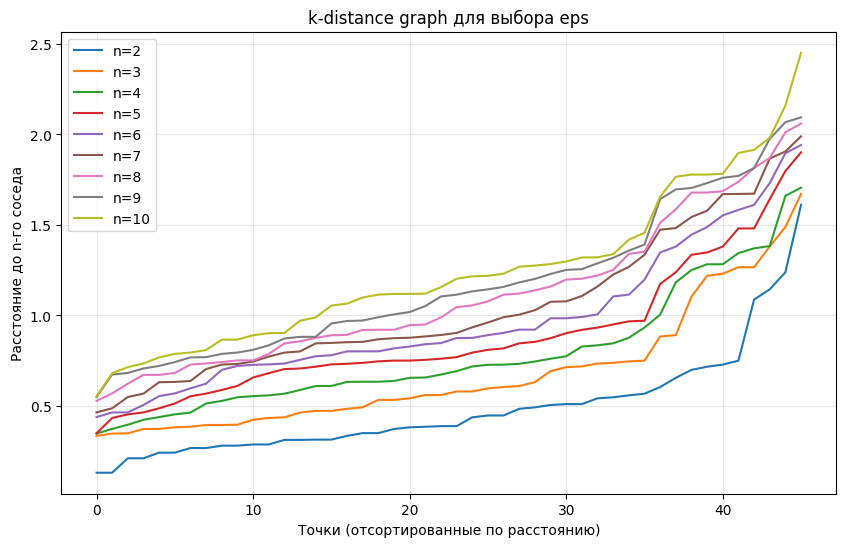

In [207]:
# Отобразить на графике кривую k-расстояний
def add_k_distance_curve(X, n, ax):
    neigh = NearestNeighbors(n_neighbors=n)
    neigh.fit(X)
    distances, _ = neigh.kneighbors(X)
    k_dist = np.sort(distances[:, n - 1], axis=0)
    ax.plot(k_dist, label=f'n={n}')


X = df_scaled[NUM_COLS].to_numpy()
n_values = range(2, 11)

fig, ax = plt.subplots(figsize=(10, 6))
for n in n_values:
    add_k_distance_curve(X, n, ax)

ax.set_xlabel('Точки (отсортированные по расстоянию)')
ax.set_ylabel('Расстояние до n-го соседа')
ax.set_title('k-distance graph для выбора eps')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

По графикам видно, что расстояния до соседей лежат в промежутке от 0.1 до 2.5.  
По этому же графику можно попробовать выбирать оптимальные eps для разных n - там где происходит резкое возрастание расстояния до соседа. Это значение зависит от n.  
Для графиков с n=2..4 eps выглядит оптимальным в районе 0.6-1.3

In [208]:
# Оценка метрик для DBSCAN для одной пары (eps, min_samples)
def evaluate_dbscan_single(X, eps, min_samples):
    db = DBSCAN(eps=eps, min_samples=min_samples)
    labels = db.fit_predict(X)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())

    mask = labels != -1
    if n_clusters > 1 and mask.sum() > 1:
        sil = silhouette_score(X[mask], labels[mask])
        ch = calinski_harabasz_score(X[mask], labels[mask])
        dav = davies_bouldin_score(X[mask], labels[mask])
    else:
        sil = ch = dav = np.nan

    return {
        'eps': eps,
        'min_samples': min_samples,
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'silhouette': sil,
        'calinski': ch,
        'davies': dav
    }


eps_values = np.arange(0.5, 3, 0.1)
min_samples_values = range(2, 11)

dbscan_results = []
for eps in eps_values:
    for n in min_samples_values:
        dbscan_results.append(evaluate_dbscan_single(X, eps, n))

dbscan_results = pd.DataFrame(dbscan_results)
# Сортируем по силуэту
dbscan_results_sorted = dbscan_results.sort_values('silhouette', ascending=False)
display(dbscan_results_sorted.head(20))

,eps,min_samples,n_clusters,n_noise,silhouette,calinski,davies
13,0.6,6,2,28,0.726264,90.060451,0.372791
12,0.6,5,2,28,0.726264,90.060451,0.372791
22,0.7,6,2,24,0.676761,67.603149,0.423716
33,0.8,8,2,19,0.628186,72.400633,0.544448
32,0.8,7,2,17,0.621251,75.183042,0.551191
21,0.7,5,3,21,0.575886,48.256983,0.573703
43,0.9,9,2,14,0.568232,64.930620,0.620668
10,0.6,3,2,16,0.553765,55.929400,0.666187
42,0.9,8,2,12,0.542189,60.443037,0.671837
19,0.7,3,2,11,0.540018,59.984356,0.664171


Важное замечание - шумовые точки не влияют на метрики, поэтому очевидно в верху таблицы окажутся параметры при которых много шумовых точек.  
Попытаемся ограничить число шумовых точек.

In [209]:
# Выбирает из таблицы подходящие параметры и отображает на графике
def plot_dbscan(results, max_noise: int, min_clus: int):
    best_row = results[
        (results['n_clusters'] >= min_clus) &
        (results['n_noise'] <= max_noise)
    ].iloc[0]

    best_eps = best_row['eps']
    best_min_samples = int(best_row['min_samples'])
    print(f"Лучшие параметры DBSCAN: eps={best_eps:.2f}, min_samples={best_min_samples}")
    print(f"Число кластеров: {best_row['n_clusters']}, шумовых точек: {best_row['n_noise']}")

    db_best = DBSCAN(eps=best_eps, min_samples=best_min_samples)
    labels_best = db_best.fit_predict(X)

    X_pca = pca_fit(df_scaled)
    fig, ax = plt.subplots(figsize=(8, 5))
    for cl in sorted(set(labels_best)):
        mask = (labels_best == cl)
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Кл. {cl}' if cl != -1 else 'Шум')
    ax.set_title(f'DBSCAN: eps={best_eps:.2f}, min_samples={best_min_samples}')
    ax.set_xlabel('Главная компонента 1')
    ax.set_ylabel('Главная компонента 2')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.show()

    return labels_best

Лучшие параметры DBSCAN: eps=0.60, min_samples=6
Число кластеров: 2.0, шумовых точек: 28.0


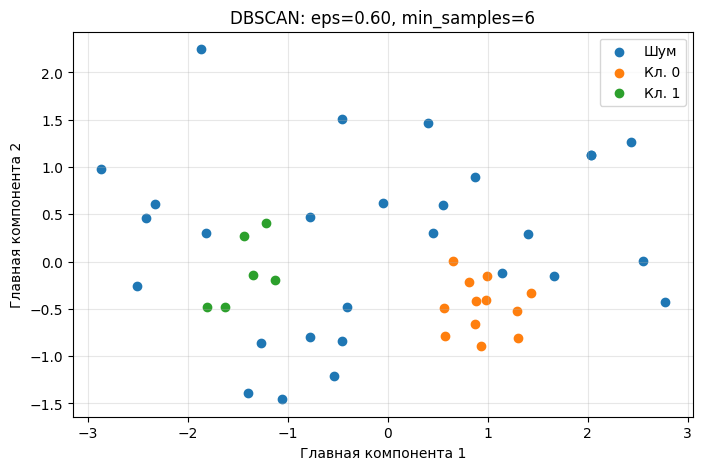

array([ 0, -1, -1, -1,  0,  1,  1, -1, -1,  0,  0,  0, -1, -1, -1, -1,  1,
       -1, -1, -1,  0, -1, -1,  0, -1,  1,  0,  0,  1, -1, -1, -1, -1,  0,
       -1, -1, -1,  1, -1,  0, -1, -1, -1, -1,  0, -1])

In [210]:
# Посмотрим без ограничений
plot_dbscan(dbscan_results_sorted, 100, 2)

Лучшие параметры DBSCAN: eps=1.00, min_samples=9
Число кластеров: 2.0, шумовых точек: 10.0


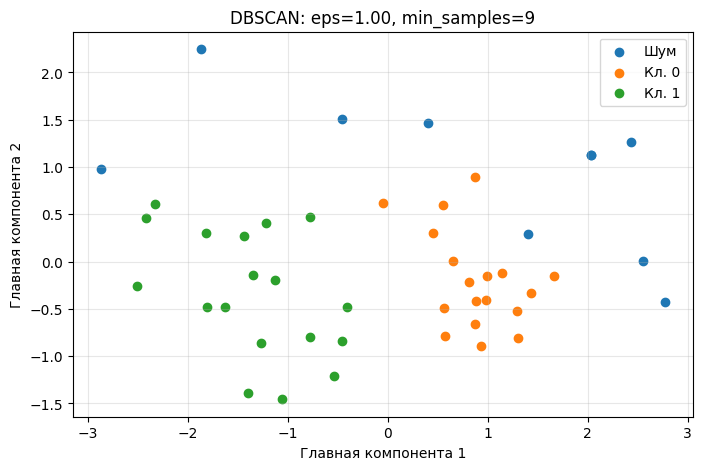

array([ 0,  1,  1,  1,  0,  1,  1,  0,  0,  0,  0,  0, -1, -1, -1,  0,  1,
        1,  1,  1,  0, -1,  0,  0, -1,  1,  0,  0,  1,  0,  1, -1,  1,  0,
        1,  1,  1,  1, -1,  0, -1,  1, -1,  0,  0, -1])

In [224]:
# Ограничим шум
plot_dbscan(dbscan_results_sorted, 10, 2)

Лучшие параметры DBSCAN: eps=0.80, min_samples=2
Число кластеров: 4.0, шумовых точек: 4.0


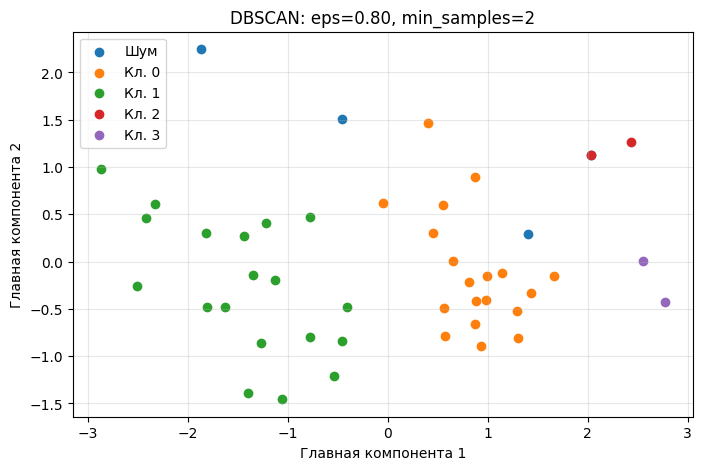

array([ 0,  1,  1,  1,  0,  1,  1,  0,  0,  0,  0,  0,  2,  3, -1,  0,  1,
        1,  1,  1,  0,  0,  0,  0,  1,  1,  0,  0,  1,  0,  1,  3,  1,  0,
        1,  1,  1,  1, -1,  0, -1,  1, -1,  0,  0,  2])

In [212]:
# Ограничим шум сильнее
plot_dbscan(dbscan_results_sorted, 5, 2)

Лучшие параметры DBSCAN: eps=0.70, min_samples=2
Число кластеров: 4.0, шумовых точек: 7.0


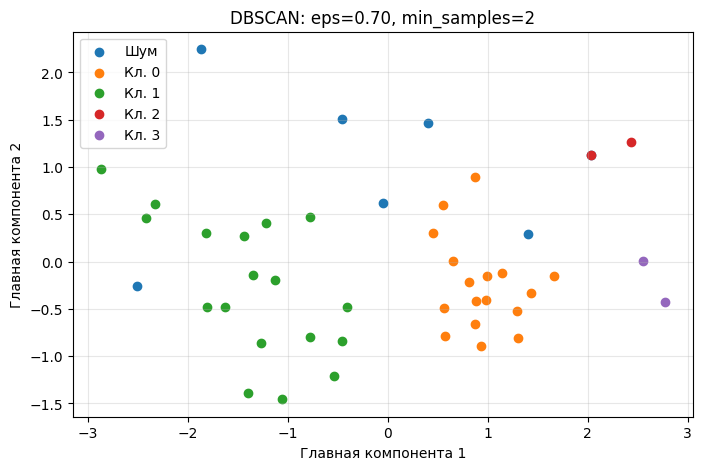

array([ 0,  1,  1, -1,  0,  1,  1,  0,  0,  0,  0,  0,  2,  3, -1, -1,  1,
        1,  1,  1,  0, -1,  0,  0,  1,  1,  0,  0,  1,  0,  1,  3,  1,  0,
        1,  1,  1,  1, -1,  0, -1,  1, -1,  0,  0,  2])

In [213]:
# Ограничим кластеры
plot_dbscan(dbscan_results_sorted, 10, 4)

Лучшие параметры DBSCAN: eps=0.60, min_samples=2
Число кластеров: 5.0, шумовых точек: 10.0


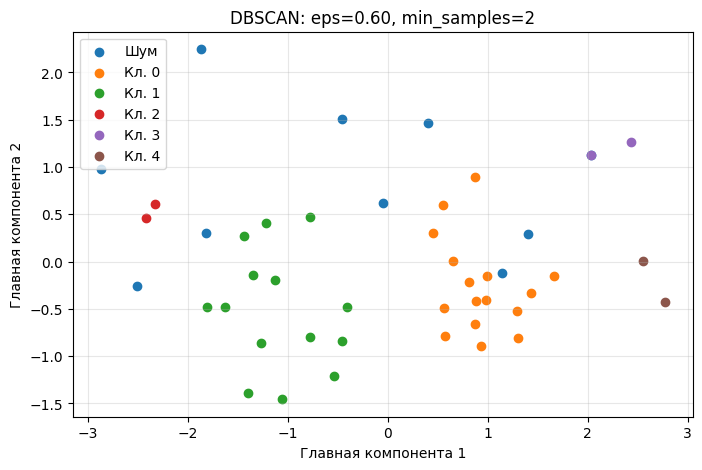

array([ 0,  1,  2, -1,  0,  1,  1,  0,  0,  0,  0,  0,  3,  4, -1, -1,  1,
        2,  1,  1,  0, -1, -1,  0, -1,  1,  0,  0,  1,  0,  1,  4, -1,  0,
        1,  1,  1,  1, -1,  0, -1,  1, -1,  0,  0,  3])

In [214]:
# Ограничим кластеры сильнее
plot_dbscan(dbscan_results_sorted, 10, 5)

У нас не получется разбить кластеры на такие же группы, как были при дендрограммах и K-Means. Это связано с тем, что у DBSCAN есть возможность полностью отсекать шумовые точки полностью.

Попробуем выполнить интерпретацию найденных классов

DBSCAN - 2 группы  
-1 - Шумовые, сюда попали Гонконг (с очень большими часами работы) и Женева (с очень большими зарплатами) и другие  
0 - Низкая нагрузка, высокие цены и зарплаты. Мажоры  
1 - Высокая нагрузка, очень низкие цены и зарплаты. Работяги  


Лучшие параметры DBSCAN: eps=1.00, min_samples=9
Число кластеров: 2.0, шумовых точек: 10.0


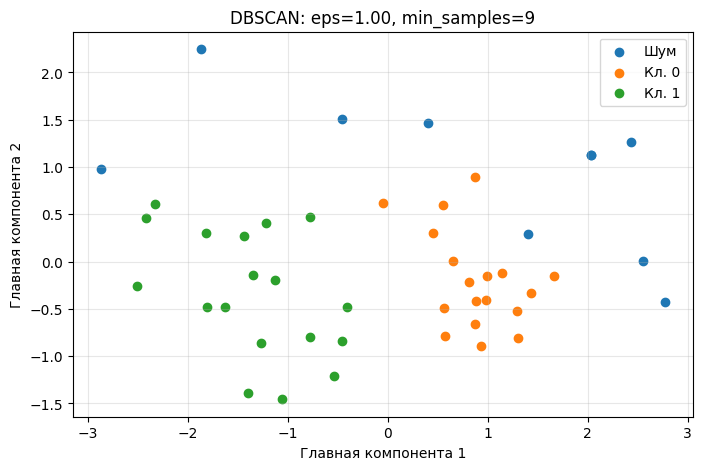

,n,Work,Price,Salary,cities
cluster,,,,,
-1,10,0.43,1.03,0.67,"Geneva, Helsinki, Hong_Kong, Los_Angeles, Mani..."
0,18,-0.60,0.35,0.61,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
1,18,0.36,-0.92,-0.99,"Athens, Bogota, Bombay, Buenos_Aires, Caracas,..."


In [215]:
labels_best = plot_dbscan(dbscan_results_sorted, 10, 2)
stats_db = cluster_stats(df_scaled, labels_best)
display(stats_db)

DBSCAN - 4 группы  
-1 - Шумовые, сюда попали Гон-Конг (с очень большими часами работы) и другие  
0 - Низкая нагрузка, высокие цены и зарплаты. Мажоры  
1 - Высокая нагрузка, очень низкие цены и зарплаты. Работяги  
2 - Средняя нагрузка, очень высокие цены и крайне высокие зарплаты. Золотые воротнички  
3 - Крайне низкая нагрузка, очень высокие цены и высокие зарплаты. Северяне  


Лучшие параметры DBSCAN: eps=0.70, min_samples=2
Число кластеров: 4.0, шумовых точек: 7.0


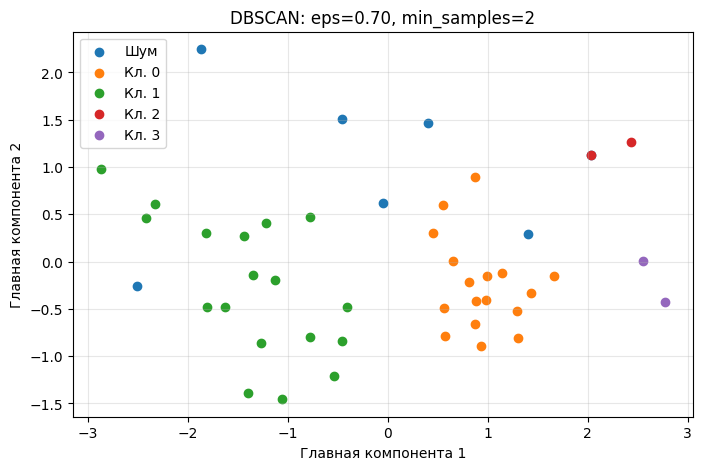

,n,Work,Price,Salary,cities
cluster,,,,,
-1,7,0.95,0.44,0.06,"Bombay, Hong_Kong, Houston, Los_Angeles, Stock..."
0,17,-0.67,0.36,0.63,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."
1,18,0.43,-0.89,-0.99,"Athens, Bogota, Buenos_Aires, Caracas, Johanne..."
2,2,-0.03,1.32,2.27,"Geneva, Zurich"
3,2,-1.48,2.10,1.05,"Helsinki, Oslo"


In [216]:
labels_best = plot_dbscan(dbscan_results_sorted, 10, 3)
stats_db = cluster_stats(df_scaled, labels_best)
display(stats_db)

Теперь попробуем сравнить все рассмотренные методы по метрикам в одной таблице

In [217]:
# Считает метрики для одной разметки
def get_metrics_single(X, labels):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())

    mask = labels != -1
    if n_clusters > 1 and mask.sum() > 1:
        sil = silhouette_score(X[mask], labels[mask])
        ch = calinski_harabasz_score(X[mask], labels[mask])
        dav = davies_bouldin_score(X[mask], labels[mask])
    else:
        sil = ch = dav = np.nan

    return n_clusters, n_noise, sil, ch, dav


summary = []

# 1) Иерархическая кластеризация
hier_linkages = ["single", "complete", "average", "ward"]
hier_k = [8, 4, 3, 4]

for method, k in zip(hier_linkages, hier_k):
    _, labels = get_clusters(df_scaled, method, "euclidean", k)
    n_clusters, n_noise, sil, ch, dav = get_metrics_single(X, labels)
    summary.append({
        'Метод': f'Иерархический ({method})',
        'Параметры': f'k={k}',
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'silhouette': sil,
        'calinski': ch,
        'davies': dav
    })

# 2) K-Means
for k in range(2, 4):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X)
    n_clusters, n_noise, sil, ch, dav = get_metrics_single(X, labels)
    summary.append({
        'Метод': 'K-Means',
        'Параметры': f'k={k}',
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'silhouette': sil,
        'calinski': ch,
        'davies': dav
    })

# 3) DBSCAN (лучшие параметры)
eps_vals = [1.0, 0.7]
ns = [9, 2]

for eps, min_samples in zip(eps_vals, ns):
    n_clusters, n_noise, sil, ch, dav = get_metrics_single(X, labels_best)
    summary.append({
        'Метод': 'DBSCAN',
        'Параметры': f'eps={eps}, min_samples={min_samples}',
        'n_clusters': n_clusters,
        'n_noise': n_noise,
        'silhouette': sil,
        'calinski': ch,
        'davies': dav
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

,Метод,Параметры,n_clusters,n_noise,silhouette,calinski,davies
0,Иерархический (single),k=8,8,0,0.307315,17.849954,0.503734
1,Иерархический (complete),k=4,4,0,0.365753,40.341690,1.062935
2,Иерархический (average),k=3,3,0,0.419660,35.028433,0.790542
3,Иерархический (ward),k=4,4,0,0.355110,38.929987,1.002428
4,K-Means,k=2,2,0,0.470499,55.351023,0.807622
5,K-Means,k=3,3,0,0.387546,41.146417,0.904805
6,DBSCAN,"eps=1.0, min_samples=9",4,7,0.495650,35.411852,0.549433
7,DBSCAN,"eps=0.7, min_samples=2",4,7,0.495650,35.411852,0.549433


В зависимости от того, какую метрику мы считаем наиболее важной, меняется трийка лучших методов.

In [218]:
summary_df_sorted = summary_df.sort_values('silhouette', ascending=False)
display(summary_df_sorted.head(3))

,Метод,Параметры,n_clusters,n_noise,silhouette,calinski,davies
6,DBSCAN,"eps=1.0, min_samples=9",4,7,0.495650,35.411852,0.549433
7,DBSCAN,"eps=0.7, min_samples=2",4,7,0.495650,35.411852,0.549433
4,K-Means,k=2,2,0,0.470499,55.351023,0.807622


In [219]:
summary_df_sorted2 = summary_df.sort_values('calinski', ascending=False)
display(summary_df_sorted2.head(3))

,Метод,Параметры,n_clusters,n_noise,silhouette,calinski,davies
4,K-Means,k=2,2,0,0.470499,55.351023,0.807622
5,K-Means,k=3,3,0,0.387546,41.146417,0.904805
1,Иерархический (complete),k=4,4,0,0.365753,40.341690,1.062935


In [220]:
summary_df_sorted = summary_df.sort_values('davies', ascending=True)
display(summary_df_sorted.head(3))

,Метод,Параметры,n_clusters,n_noise,silhouette,calinski,davies
0,Иерархический (single),k=8,8,0,0.307315,17.849954,0.503734
7,DBSCAN,"eps=0.7, min_samples=2",4,7,0.495650,35.411852,0.549433
6,DBSCAN,"eps=1.0, min_samples=9",4,7,0.495650,35.411852,0.549433


# Выводы
Лаб 1:
- Пропуски были закодированы как -9999. Удалены две строки (Каир и Джакарта), в которых отсутствовали два из трёх показателей. Итоговая выборка — 46 городов.
- Обнаружена сильная положительная корреляция между индексом цен и индексом зарплат: в городах с высокими доходами выше и стоимость жизни.
- На проекции на 2 главные компоненты видны две крупные группы и несколько отдельных точек, что указывает на наличие как минимум двух кластеров и возможных выбросов.
- В зависимости от выбранного метода кластеризации группировка происходила по-разному, что позволяло посмотреть на данные с разных сторон.
    - Single чувствителен к выбросам - городам с уникальными экономическими профилями.
- Можно интерпретировать разные группы: работяги, трудоголики, мажоры, золотые воротнички.
- Гипотезы
    - Города можно разбить на кластеры.
    - Присутствуют сильно отличающиеся города.

Лаб2:
- Применён метод K-Means
  - Он хорошо отрабатывает на любом (разумном) числе кластеров, и каждый из них можно по-своему интерпретировать
  - Метрики имеют лучшие значения на 2 больших группах: мажоры и работяги
  - При увеличении числа кластеров появляются более дробные интерпретации
- Интересно, что метрики пошли в противоречие с интерпретацией дендрограмм - они заявляют, что тут точно не 4 класса

Лаб 3:
- Применён метод DBSCAN
  - Позволяет выделять кластеры произвольной формы
  - Автоматически определяет выбросы
  - Не требует выбора количества кластеров (их число определяется автоматически), но требует настройки других параметров (расстояния и числа соседей)
  - Параметры подбираются на основе их перебора с оценкой метрик и ограничением по количеству кластеров и максимальному числу шумовых точек
  - Не удалось разбить на такие же 4 группы - шумовые точки исключались, что требовало более плотных кластеров
  - Лучшие метрики получились при 2 кластерах


Выбор финального разделения на кластеры сильно зависит от метода, который мы используем, а также от того насколько сильно мы ценим определённые метрики.